Choose an image file to upload...


Saving aloo.jpeg to aloo.jpeg
Uploaded: aloo.jpeg
{
    "name": "api.receive",
    "context": {
        "trace_id": "0xf5d73e636030a057d4ab047a8858209b",
        "span_id": "0x019bd2ed00446ab4",
        "trace_state": "[]"
    },
    "kind": "SpanKind.INTERNAL",
    "parent_id": "0x986d74e6fe51a0e1",
    "start_time": "2026-11-13T08:14:43.988910Z",
    "end_time": "2026-11-13T08:14:43.988946Z",
    "status": {
        "status_code": "UNSET"
    },
    "attributes": {
        "http.filename": "aloo.jpeg",
        "image.size_bytes": 48474
    },
    "events": [],
    "links": [],
    "resource": {
        "attributes": {
            "telemetry.sdk.language": "python",
            "telemetry.sdk.name": "opentelemetry",
            "telemetry.sdk.version": "1.42.1",
            "service.name": "image-inference-service"
        },
        "schema_url": ""
    }
}
{
    "name": "image.preprocess",
    "context": {
        "trace_id": "0xf5d73e636030a057d4ab047a8858209b",
        "span_id": 

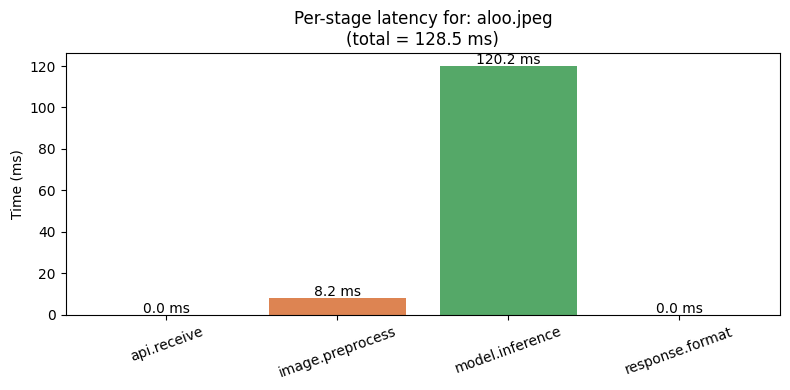

In [ ]:


!pip install -q opentelemetry-api opentelemetry-sdk Pillow matplotlib

import io, time, json
from PIL import Image
import matplotlib.pyplot as plt

from opentelemetry import trace
from opentelemetry.sdk.trace import TracerProvider
from opentelemetry.sdk.trace.export import BatchSpanProcessor, ConsoleSpanExporter
from opentelemetry.sdk.resources import Resource

# ---------- 1. TRACING SETUP ----------
provider = TracerProvider(resource=Resource.create({"service.name": "image-inference-service"}))
provider.add_span_processor(BatchSpanProcessor(ConsoleSpanExporter()))
trace.set_tracer_provider(provider)
tracer = trace.get_tracer("image-tracer")

# ---------- 2. FAKE MODEL ----------
def run_model(image):
    time.sleep(0.12)
    return {"class": "cat", "confidence": 0.92}

# ---------- 3. UPLOAD YOUR IMAGE ----------
from google.colab import files
print("Choose an image file to upload...")
uploaded = files.upload()
filename = list(uploaded.keys())[0]
print(f"Uploaded: {filename}")

with open(filename, "rb") as f:
    raw_bytes = f.read()

# ---------- 4. TRACE THE PIPELINE (one trace) ----------
timings = {}   # store duration per stage for the graph

with tracer.start_as_current_span("predict.request") as root:

    # STAGE 1: API INPUT
    with tracer.start_as_current_span("api.receive") as span:
        t0 = time.time()
        contents = raw_bytes
        span.set_attribute("http.filename", filename)
        span.set_attribute("image.size_bytes", len(contents))
        timings["api.receive"] = (time.time() - t0) * 1000

    # STAGE 2: PREPROCESSING
    with tracer.start_as_current_span("image.preprocess") as span:
        t0 = time.time()
        img = Image.open(io.BytesIO(contents)).convert("RGB")
        span.set_attribute("image.original_size", str(img.size))
        img = img.resize((224, 224))
        span.set_attribute("image.resized_to", "224x224")
        timings["image.preprocess"] = (time.time() - t0) * 1000

    # STAGE 3: MODEL EXECUTION
    with tracer.start_as_current_span("model.inference") as span:
        t0 = time.time()
        result = run_model(img)
        span.set_attribute("model.name", "fake-resnet50")
        span.set_attribute("model.inference_ms", round((time.time() - t0) * 1000, 2))
        span.set_attribute("model.confidence", result["confidence"])
        timings["model.inference"] = (time.time() - t0) * 1000

    # STAGE 4: RESPONSE
    with tracer.start_as_current_span("response.format") as span:
        t0 = time.time()
        span.set_attribute("response.class", result["class"])
        response = {"prediction": result["class"], "confidence": result["confidence"]}
        timings["response.format"] = (time.time() - t0) * 1000

provider.force_flush()
time.sleep(1)

# ---------- 5. FINAL RESPONSE ----------
print("\n=== FINAL RESPONSE ===")
print(json.dumps(response, indent=2))

# ---------- 6. BAR CHART OF STAGE TIMINGS ----------
stages = list(timings.keys())
values = [timings[s] for s in stages]

plt.figure(figsize=(8, 4))
bars = plt.bar(stages, values, color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, v + 1, f"{v:.1f} ms",
             ha="center", fontsize=10)
plt.ylabel("Time (ms)")
plt.title(f"Per-stage latency for: {filename}\n"
          f"(total = {sum(values):.1f} ms)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()